# 01 · Exploratory Data Analysis - IBM Telco Customer Churn

**Goal:** understand who churns and why, check data quality, and motivate the feature
engineering used in `src/churn/features.py`.

Dataset: 7,043 customers of a fictional telecom provider, 21 columns: demographics, account
details, subscribed services, and the target `Churn` (left within the last month).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from churn.data import load_raw, clean
from churn import config

STAY, CHURN = "#2a78d6", "#eb6834"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = config.FIGURES_DIR; FIG.mkdir(parents=True, exist_ok=True)

raw = load_raw()
raw.shape

(7043, 21)

## 1. Data quality

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# TotalCharges is stored as text; blanks hide as " " strings
blank = raw["TotalCharges"].astype(str).str.strip().eq("")
print("Blank TotalCharges:", blank.sum())
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All 11 blanks have **tenure = 0**: brand-new customers who have not been billed yet.
The right fix is `TotalCharges = 0`, not mean imputation. `clean()` does this, normalises
`SeniorCitizen` from 0/1 to No/Yes, and strips whitespace.

In [4]:
df = clean(raw)
df["churn"] = (df["Churn"] == "Yes").astype(int)
print("Duplicates:", raw.duplicated().sum(), "| duplicate IDs:", raw["customerID"].duplicated().sum())
print("Missing after cleaning:", int(df.isna().sum().sum()))
df.describe().T.round(2)

Duplicates: 0 | duplicate IDs: 0
Missing after cleaning: 0


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80
churn,7043.0,0.27,0.44,0.00,0.00,0.00,1.00,1.00


## 2. Target balance

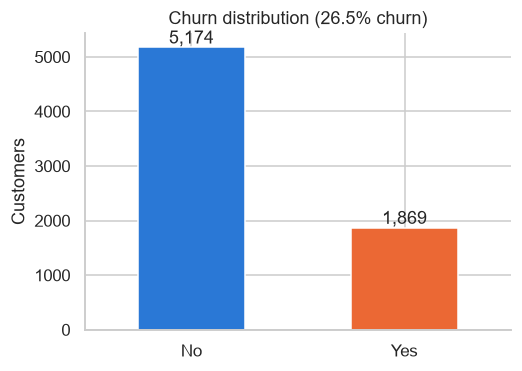

In [5]:
rate = df["churn"].mean()
ax = df["Churn"].value_counts().plot.bar(color=[STAY, CHURN], rot=0, figsize=(5, 3.5))
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set(title=f"Churn distribution ({rate:.1%} churn)", ylabel="Customers", xlabel="")
plt.savefig(FIG / "eda_target_balance.png", bbox_inches="tight"); plt.show()

**26.5% churn**: imbalanced but not extreme. Accuracy alone would be misleading (the
always-stay model scores 73.5%), so models are compared on ROC-AUC, PR-AUC, recall and F1,
and the decision threshold is tuned rather than fixed at 0.5.

## 3. Numeric features

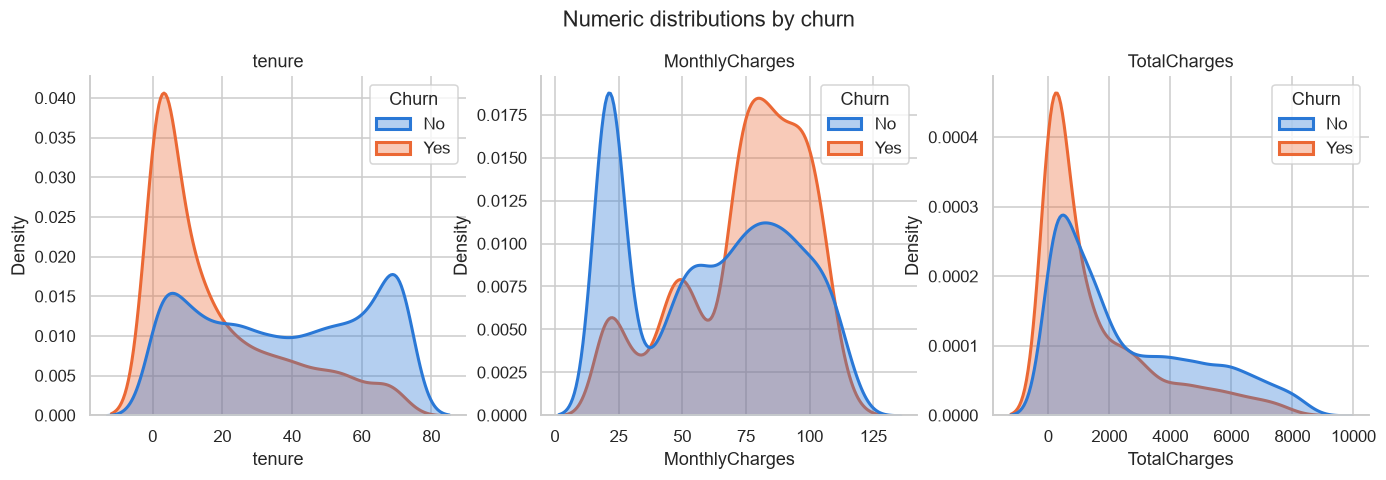

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, config.RAW_NUMERIC):
    sns.kdeplot(data=df, x=col, hue="Churn", fill=True, common_norm=False, alpha=0.35,
                palette={"No": STAY, "Yes": CHURN}, ax=ax, linewidth=2)
    ax.set_title(col)
plt.suptitle("Numeric distributions by churn", y=1.03)
plt.savefig(FIG / "eda_numeric_kde.png", bbox_inches="tight"); plt.show()
df.groupby("Churn")[config.RAW_NUMERIC].median()

- **Tenure** is the clearest signal: churners are concentrated in the first months (median
10 vs. 38 months).
- **MonthlyCharges**: churners pay more (median ~$80 vs. ~$64), with a mass of $70-$110 fiber customers.
- **TotalCharges** is mostly tenure × monthly charges, so it is strongly collinear with tenure.

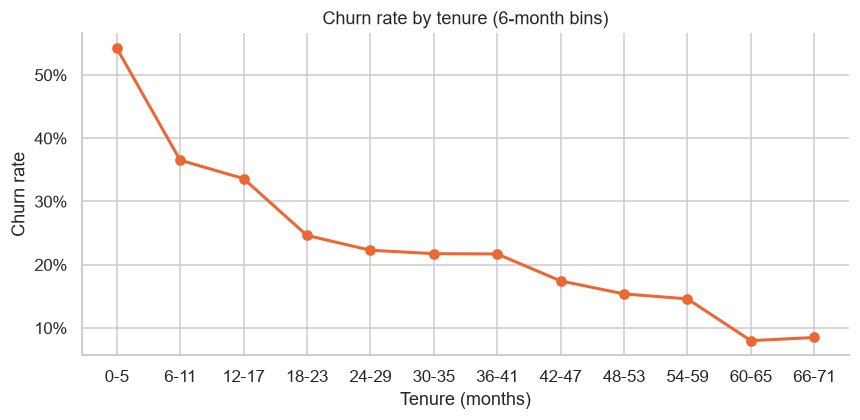

In [7]:
bins = pd.cut(df["tenure"], bins=range(0, 78, 6), right=False)
t = df.groupby(bins, observed=True)["churn"].mean()
ax = t.plot(marker="o", color=CHURN, lw=2, figsize=(9, 3.8))
ax.set(title="Churn rate by tenure (6-month bins)", ylabel="Churn rate", xlabel="Tenure (months)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{int(i.left)}-{int(i.right)-1}" for i in t.index], rotation=0)
plt.savefig(FIG / "eda_tenure_churn.png", bbox_inches="tight"); plt.show()

Churn is ~54% in the first 6 months and falls steadily, which motivates the `tenure_group` lifecycle feature and the early-life care recommendation.

## 4. Categorical features: churn rate by level

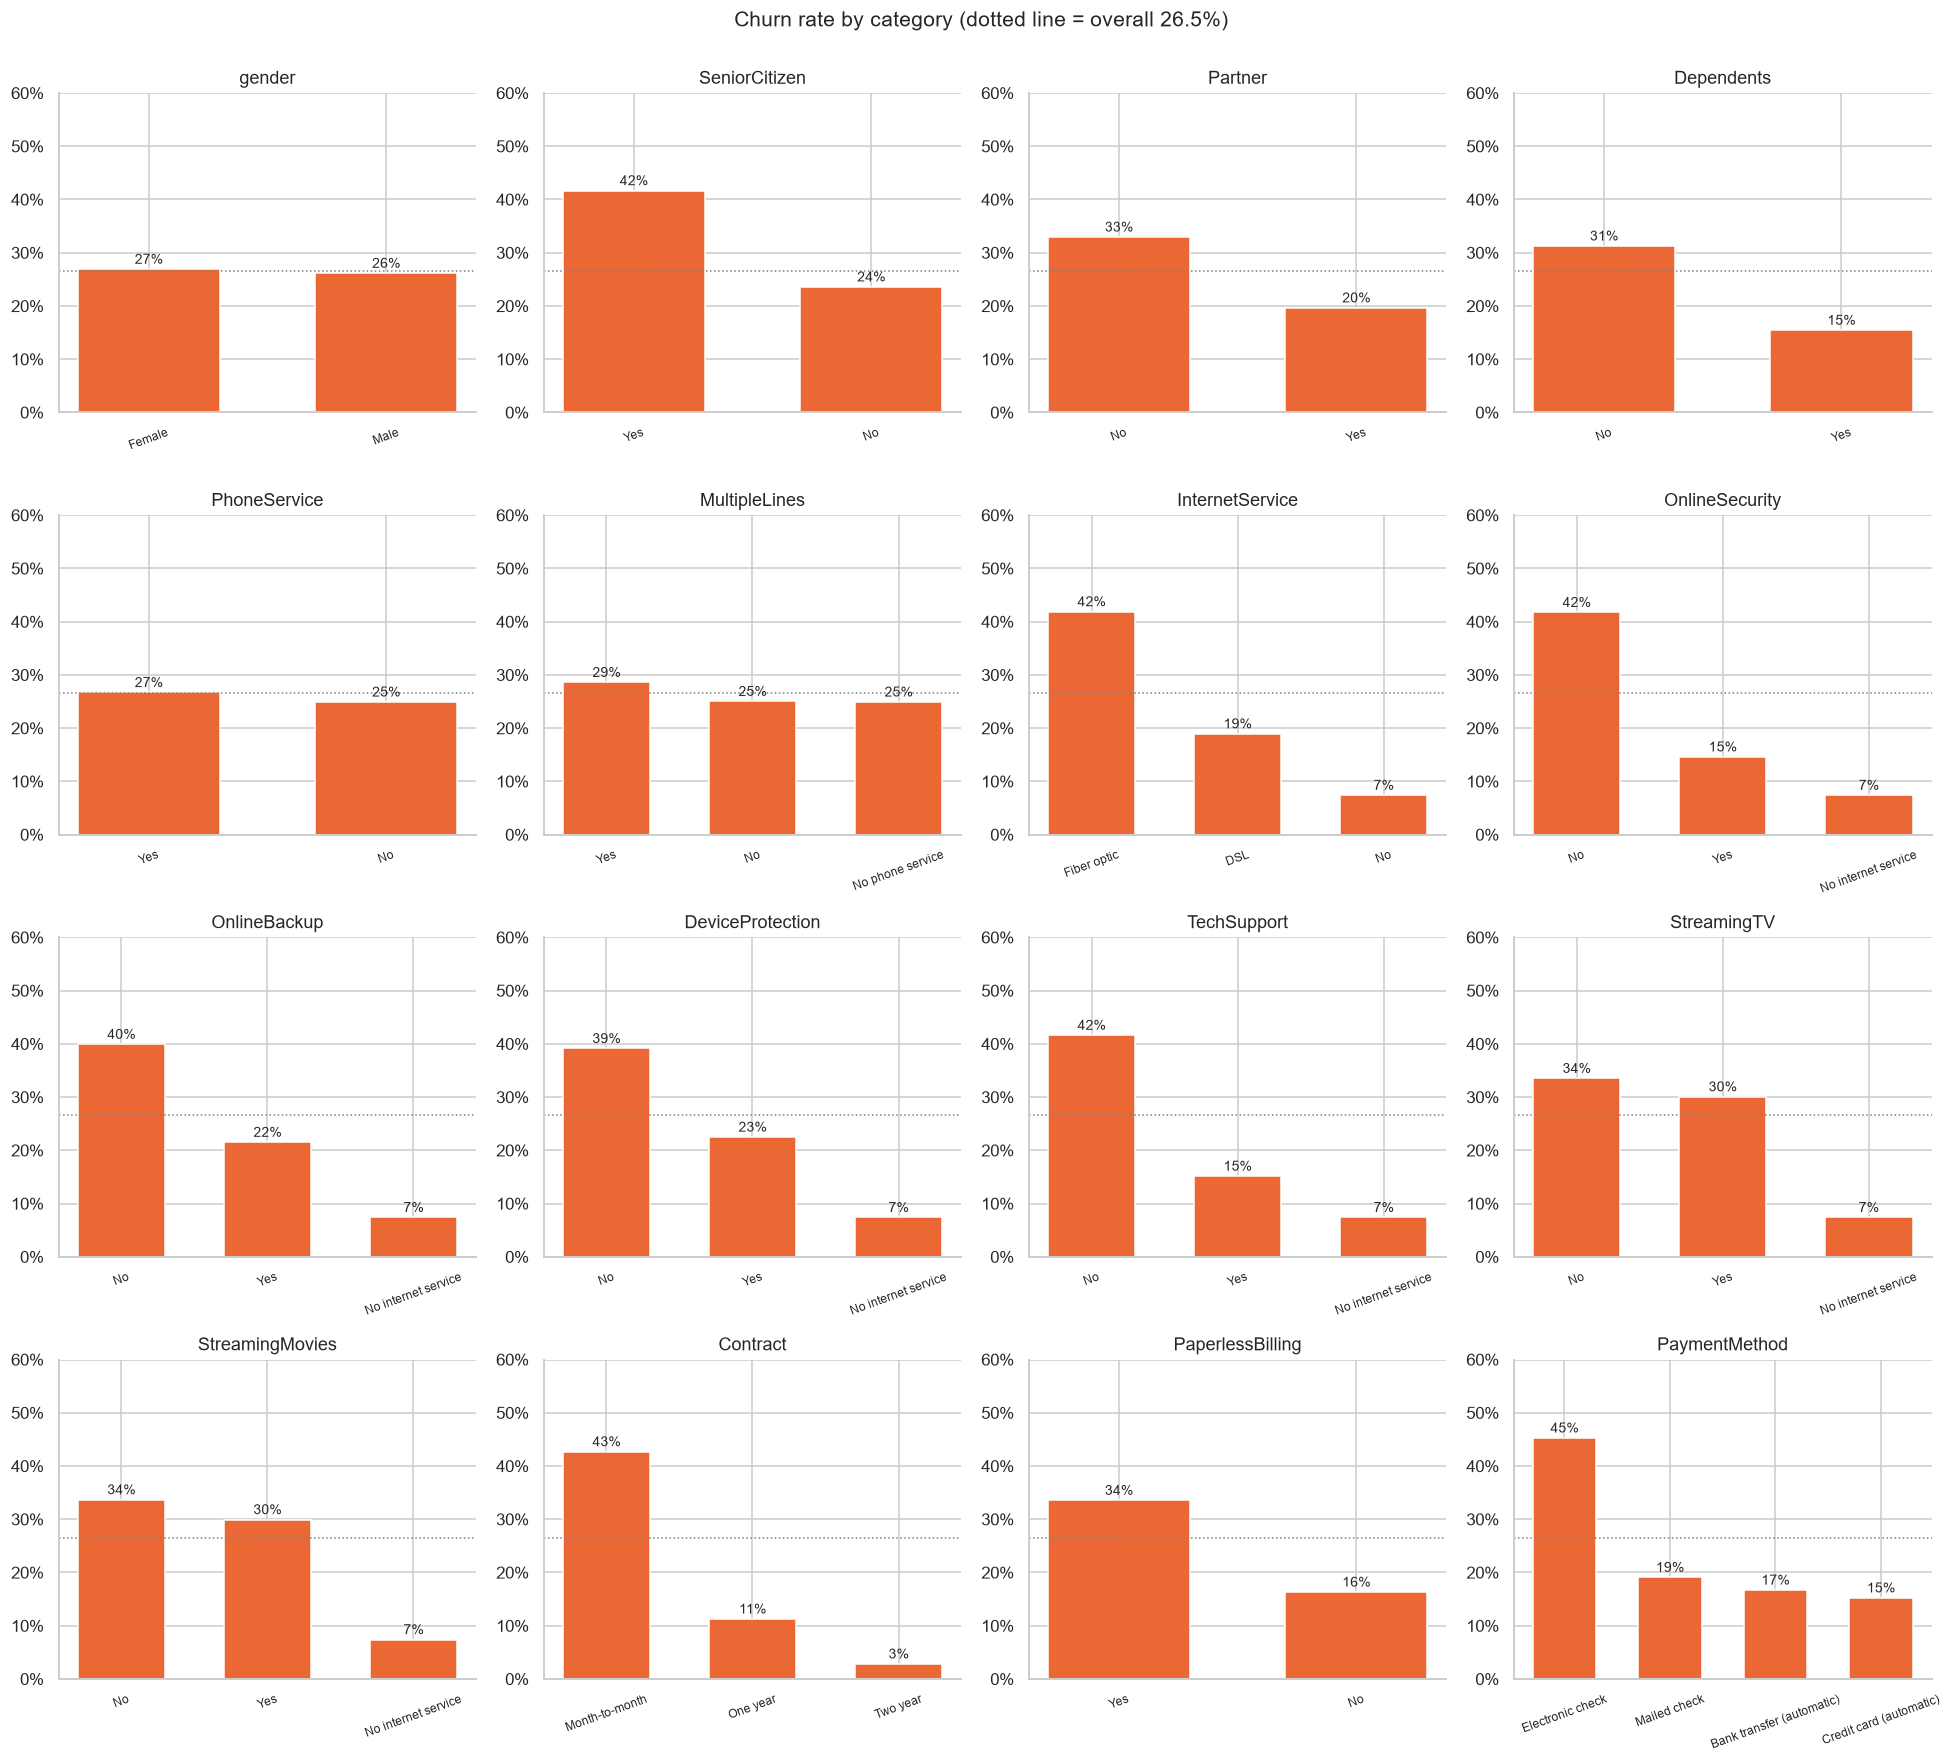

In [8]:
cats = [c for c in config.RAW_CATEGORICAL]
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, col in zip(axes.ravel(), cats):
    r = df.groupby(col)["churn"].agg(["mean", "size"]).sort_values("mean", ascending=False)
    ax.bar(r.index.astype(str), r["mean"], color=CHURN, width=0.6)
    ax.axhline(rate, color="gray", ls=":", lw=1)
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(i, m + 0.01, f"{m:.0%}", ha="center", fontsize=9)
    ax.set_title(col); ax.set_ylim(0, 0.6); ax.tick_params(axis="x", rotation=20, labelsize=8)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.suptitle("Churn rate by category (dotted line = overall 26.5%)", y=1.0, fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "eda_categorical_churn.png", bbox_inches="tight"); plt.show()

### Strength of association (Cramér's V)

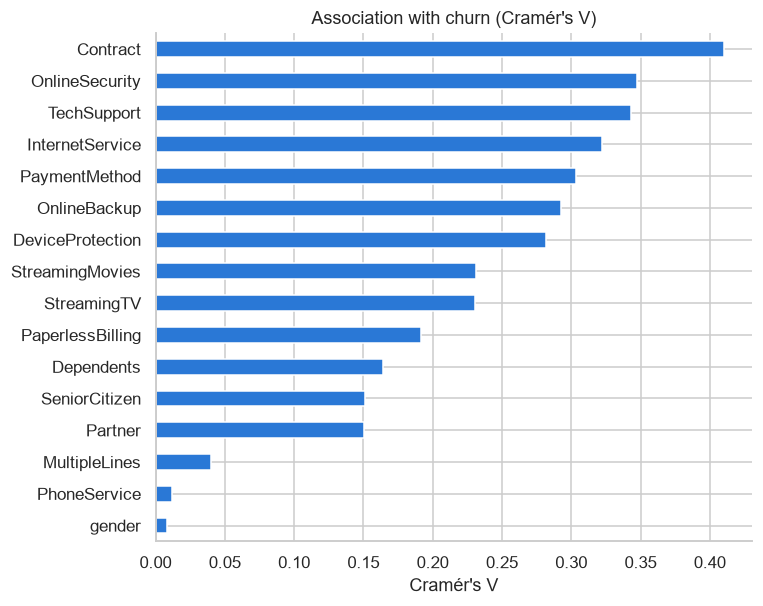

Contract            0.410
OnlineSecurity      0.347
TechSupport         0.343
InternetService     0.322
PaymentMethod       0.303
OnlineBackup        0.292
DeviceProtection    0.282
StreamingMovies     0.231
StreamingTV         0.231
PaperlessBilling    0.192
Dependents          0.164
SeniorCitizen       0.151
Partner             0.150
MultipleLines       0.040
PhoneService        0.012
gender              0.009
dtype: float64

In [9]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

assoc = pd.Series({c: cramers_v(df[c], df["Churn"]) for c in cats}).sort_values(ascending=False)
ax = assoc.iloc[::-1].plot.barh(color=STAY, figsize=(7, 6))
ax.set(title="Association with churn (Cramér's V)", xlabel="Cramér's V")
plt.savefig(FIG / "eda_cramers_v.png", bbox_inches="tight"); plt.show()
assoc.round(3)

**Key findings**

| Driver | Highest-risk level | Churn | Lowest-risk level | Churn |
|---|---|---|---|---|
| Contract | Month-to-month | 43% | Two year | 3% |
| Payment | Electronic check | 45% | Credit card (auto) | 15% |
| Internet | Fiber optic | 42% | No internet | 7% |
| Online security | No | 42% | Yes | 15% |
| Tech support | No | 42% | Yes | 15% |
| Senior citizen | Yes | 42% | No | 24% |

`gender` and `PhoneService` carry essentially no signal (V ≈ 0.01).

## 5. Interactions

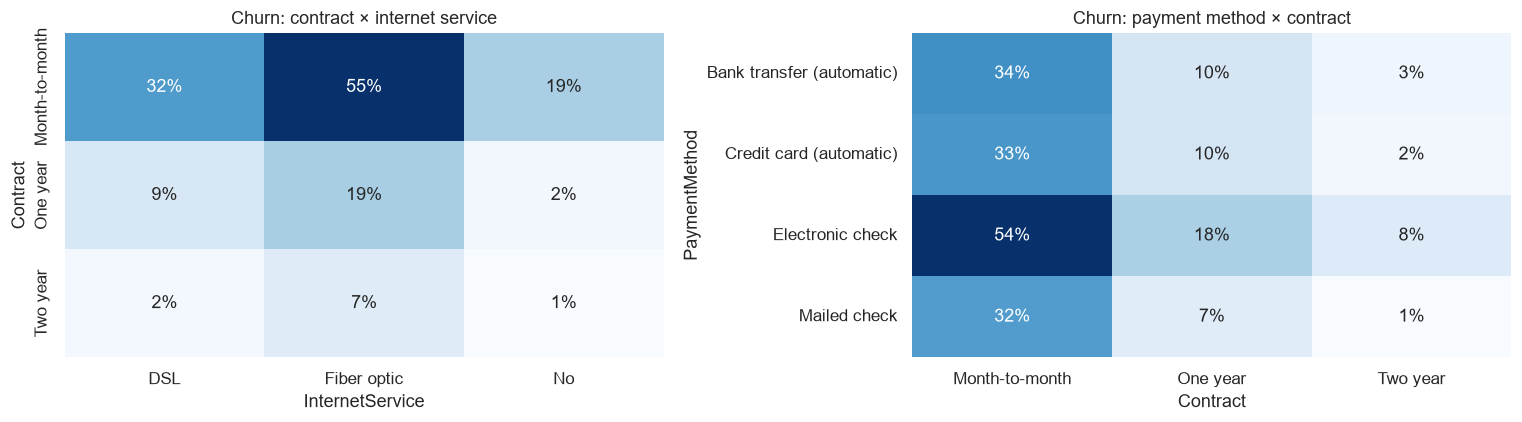

In [10]:
pivot = df.pivot_table(index="Contract", columns="InternetService", values="churn", aggfunc="mean")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Blues", ax=ax[0], cbar=False)
ax[0].set_title("Churn: contract × internet service")
pivot2 = df.pivot_table(index="PaymentMethod", columns="Contract", values="churn", aggfunc="mean")
sns.heatmap(pivot2, annot=True, fmt=".0%", cmap="Blues", ax=ax[1], cbar=False)
ax[1].set_title("Churn: payment method × contract")
plt.tight_layout(); plt.savefig(FIG / "eda_interactions.png", bbox_inches="tight"); plt.show()

Month-to-month **fiber** customers churn at ~55%. Risk compounds across dimensions,
which tree ensembles capture natively and which the logistic model approximates via the
engineered features.

## 6. Engineered features

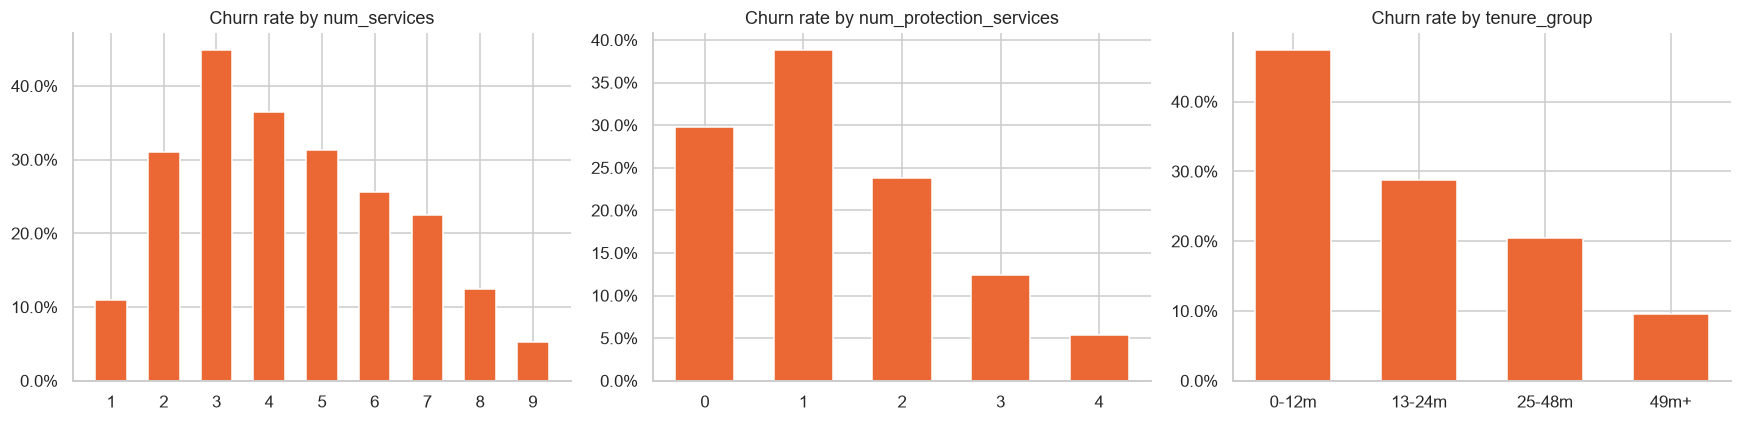

,avg_monthly_spend,charge_to_tenure_ratio,monthly_charge_delta
churn,,,
0,63.98,1.63,0.0
1,79.31,6.71,0.0


In [11]:
from churn.features import FeatureEngineer, TENURE_LABELS
fe = FeatureEngineer().transform(df[config.RAW_FEATURES])
fe["churn"] = df["churn"].values
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["num_services", "num_protection_services", "tenure_group"]):
    order = TENURE_LABELS if col == "tenure_group" else sorted(fe[col].unique())
    r = fe.groupby(col)["churn"].mean().reindex(order)
    ax.bar(r.index.astype(str), r.values, color=CHURN, width=0.6)
    ax.set_title(f"Churn rate by {col}"); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout(); plt.savefig(FIG / "eda_engineered.png", bbox_inches="tight"); plt.show()
fe.groupby("churn")[["avg_monthly_spend", "charge_to_tenure_ratio", "monthly_charge_delta"]].median().round(2)

- **Protection add-ons**: churn drops steeply from 1 add-on (39%) to 4 add-ons (5%), supporting the
  security/tech-support offers. The 0 group (30%) is lower than 1 only because it includes
  no-internet customers, who rarely churn.
- `charge_to_tenure_ratio` separates the classes far better than either raw input alone
  (expensive *and* new is the riskiest combination).
- `monthly_charge_delta` captures recent price increases.

## 7. Correlation of numeric features

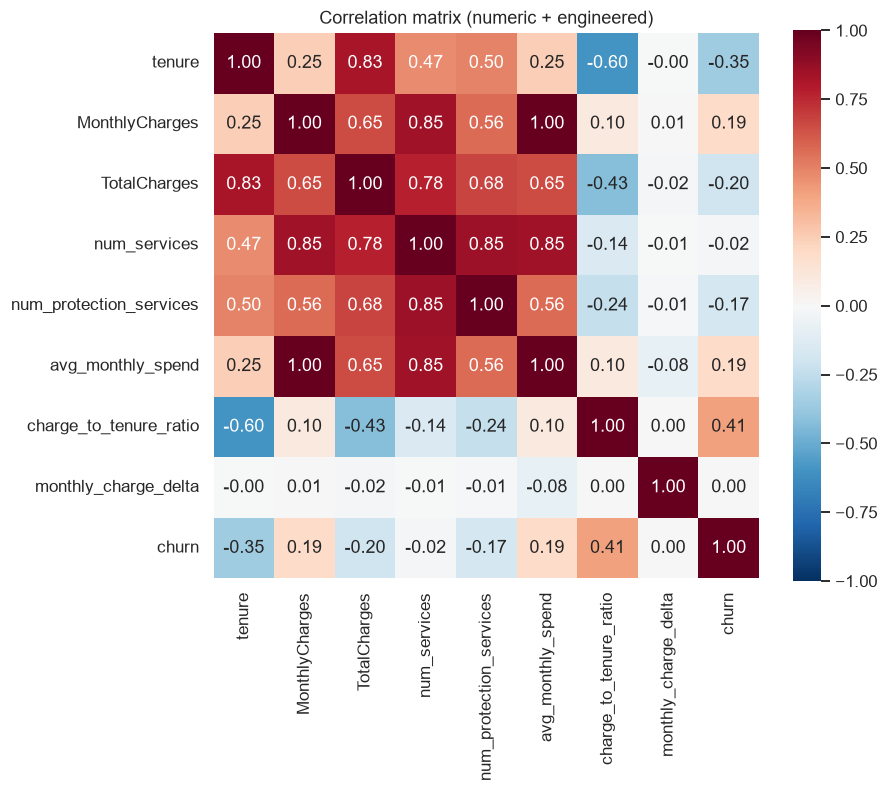

In [12]:
num = fe[config.MODEL_NUMERIC + ["churn"]]
plt.figure(figsize=(8, 6.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (numeric + engineered)")
plt.savefig(FIG / "eda_correlation.png", bbox_inches="tight"); plt.show()

`TotalCharges` is highly correlated with `tenure` (0.83). This doesn't hurt prediction, but
it splits importance between the two in linear-model coefficients, one more reason to use SHAP
on the final model rather than raw coefficients.

## Summary → modelling decisions

1. **Clean** `TotalCharges` (blank → 0 for tenure 0) and normalise `SeniorCitizen`.
2. **Imbalance (26.5%)**: stratified split, ROC-AUC/PR-AUC for selection, F1-tuned threshold;
   keep probabilities calibrated (no re-weighting) because they feed revenue-at-risk.
3. **Engineer** lifecycle, engagement (service counts), price-pressure and payment features.
4. **Retention levers** suggested by the data: contract migration, autopay, security/support
   bundles, early-life onboarding, fiber experience. These became the rules in `src/churn/recommend.py`.